# Trigonometry intuition: sine and cosine

We will start with the most important picture in trigonometry: the **unit circle**.

## What to keep in mind

If a point on the unit circle makes an angle $\theta$ with the positive $x$-axis, then its coordinates are:

$$
(\cos \theta, \sin \theta)
$$

That means:

- **cosine** tells you the horizontal position
- **sine** tells you the vertical position

So sine and cosine are not abstract formulas first. They are the **coordinates of a moving point on a circle of radius 1**.

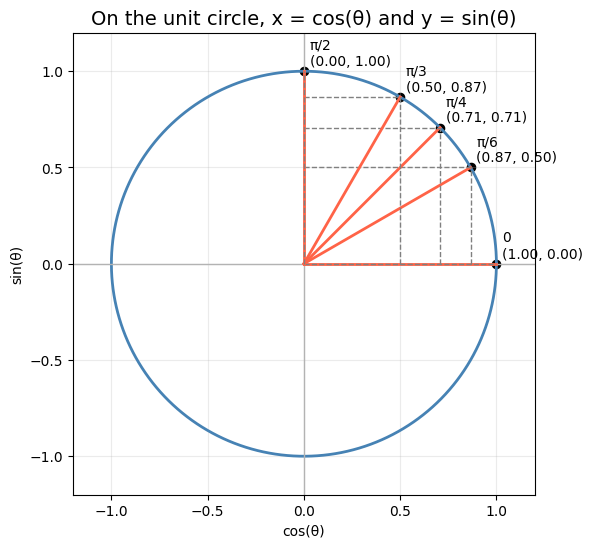

In [1]:
import numpy as np
import matplotlib.pyplot as plt

angles = np.linspace(0, 2 * np.pi, 600)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(np.cos(angles), np.sin(angles), color='steelblue', linewidth=2)
ax.axhline(0, color='0.7', linewidth=1)
ax.axvline(0, color='0.7', linewidth=1)

sample_angles = [0, np.pi/6, np.pi/4, np.pi/3, np.pi/2]
labels = ['0', 'π/6', 'π/4', 'π/3', 'π/2']

for theta, label in zip(sample_angles, labels):
    x = np.cos(theta)
    y = np.sin(theta)
    ax.plot([0, x], [0, y], color='tomato', linewidth=2)
    ax.scatter([x], [y], color='black', s=35)
    ax.text(x + 0.03, y + 0.03, f'{label}\n({x:.2f}, {y:.2f})', fontsize=10)
    ax.plot([x, x], [0, y], linestyle='--', color='gray', linewidth=1)
    ax.plot([0, x], [y, y], linestyle='--', color='gray', linewidth=1)

ax.set_title('On the unit circle, x = cos(θ) and y = sin(θ)', fontsize=14)
ax.set_xlabel('cos(θ)')
ax.set_ylabel('sin(θ)')
ax.set_aspect('equal')
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.grid(alpha=0.25)
plt.show()

## The core picture

For any angle $\theta$:

- move around the unit circle by that angle
- look at the point you land on
- the **x-coordinate** is $\cos \theta$
- the **y-coordinate** is $\sin \theta$

This gives immediate intuition:

- near $\theta = 0$, cosine is close to 1 and sine is close to 0
- near $\theta = \frac{\pi}{2}$, cosine is close to 0 and sine is close to 1
- in the left half of the circle, cosine is negative
- in the lower half of the circle, sine is negative

So the signs of sine and cosine are just telling you **which side of the axes the point is on**.

In [ ]:
import ipywidgets as widgets

curve_angles = np.linspace(0, 2 * np.pi, 600)


def show_angle(theta):
    x = np.cos(theta)
    y = np.sin(theta)    y = np.sin(theta)


    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    circle_ax = axes[0]
    circle_ax.plot(np.cos(curve_angles), np.sin(curve_angles), color='steelblue', linewidth=2)
    circle_ax.axhline(0, color='0.75', linewidth=1)
    circle_ax.axvline(0, color='0.75', linewidth=1)
    circle_ax.plot([0, x], [0, y], color='tomato', linewidth=2.5)
    circle_ax.scatter([x], [y], color='black', s=45)
    circle_ax.plot([x, x], [0, y], linestyle='--', color='gray')
    circle_ax.plot([0, x], [y, y], linestyle='--', color='gray')
    circle_ax.text(x / 2, -0.12, f'cos(θ) = {x:.3f}', ha='center', fontsize=11)
    circle_ax.text(0.12, y / 2, f'sin(θ) = {y:.3f}', va='center', fontsize=11)
    circle_ax.set_title(f'Unit circle at θ = {theta:.2f} radians')
    circle_ax.set_aspect('equal')
    circle_ax.set_xlim(-1.2, 1.2)
    circle_ax.set_ylim(-1.2, 1.2)
    circle_ax.grid(alpha=0.25)

    graph_ax = axes[1]
    graph_ax.plot(curve_angles, np.sin(curve_angles), label='sin(θ)', color='seagreen', linewidth=2)
    graph_ax.plot(curve_angles, np.cos(curve_angles), label='cos(θ)', color='darkorange', linewidth=2)
    graph_ax.axvline(theta, color='black', linestyle='--', linewidth=1)
    graph_ax.scatter([theta], [y], color='seagreen', s=40)
    graph_ax.scatter([theta], [x], color='darkorange', s=40)
    graph_ax.set_title('The same angle on the sine and cosine graphs')
    graph_ax.set_xlabel('θ (radians)')
    graph_ax.set_ylabel('value')
    graph_ax.set_xlim(0, 2 * np.pi)
    graph_ax.set_ylim(-1.15, 1.15)
    graph_ax.grid(alpha=0.25)
    graph_ax.legend()

    plt.tight_layout()
    plt.show()


slider = widgets.FloatSlider(
    value=np.pi / 4,
    min=0,
    max=2 * np.pi,
    step=0.05,
    description='θ',
    readout_format='.2f',
    continuous_update=False,
)

_ = widgets.interact(show_angle, theta=slider)

interactive(children=(FloatSlider(value=0.7853981633974483, continuous_update=False, description='θ', max=6.28…

In [6]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

animation_angles = np.linspace(0, 2 * np.pi, 120)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), dpi=90)
circle_ax, graph_ax = axes

circle_ax.plot(np.cos(curve_angles), np.sin(curve_angles), color='steelblue', linewidth=2)
circle_ax.axhline(0, color='0.75', linewidth=1)
circle_ax.axvline(0, color='0.75', linewidth=1)
circle_ax.set_title('Rotating point on the unit circle')
circle_ax.set_xlabel('cos(θ)')
circle_ax.set_ylabel('sin(θ)')
circle_ax.set_aspect('equal')
circle_ax.set_xlim(-1.2, 1.2)
circle_ax.set_ylim(-1.2, 1.2)
circle_ax.grid(alpha=0.25)

radius_line, = circle_ax.plot([], [], color='tomato', linewidth=2.5)
point, = circle_ax.plot([], [], 'o', color='black', markersize=7)
vertical_guide, = circle_ax.plot([], [], linestyle='--', color='seagreen', linewidth=1.5)
horizontal_guide, = circle_ax.plot([], [], linestyle='--', color='darkorange', linewidth=1.5)
angle_text = circle_ax.text(-1.12, 1.07, '', fontsize=10)
value_text = circle_ax.text(-1.12, 0.92, '', fontsize=10)

graph_ax.set_title('Sine and cosine traced over time')
graph_ax.set_xlabel('θ (radians)')
graph_ax.set_ylabel('value')
graph_ax.set_xlim(0, 2 * np.pi)
graph_ax.set_ylim(-1.15, 1.15)
graph_ax.grid(alpha=0.25)
graph_ax.plot(curve_angles, np.sin(curve_angles), color='seagreen', linewidth=1.2, alpha=0.18)
graph_ax.plot(curve_angles, np.cos(curve_angles), color='darkorange', linewidth=1.2, alpha=0.18)

sine_trace, = graph_ax.plot([], [], color='seagreen', linewidth=2.5, label='sin(θ)')
cosine_trace, = graph_ax.plot([], [], color='darkorange', linewidth=2.5, label='cos(θ)')
sine_point, = graph_ax.plot([], [], 'o', color='seagreen', markersize=6)
cosine_point, = graph_ax.plot([], [], 'o', color='darkorange', markersize=6)
time_line = graph_ax.axvline(0, color='black', linestyle='--', linewidth=1)
graph_ax.legend(loc='upper right')

plt.tight_layout()


def init():
    radius_line.set_data([], [])
    point.set_data([], [])
    vertical_guide.set_data([], [])
    horizontal_guide.set_data([], [])
    sine_trace.set_data([], [])
    cosine_trace.set_data([], [])
    sine_point.set_data([], [])
    cosine_point.set_data([], [])
    time_line.set_xdata([0, 0])
    angle_text.set_text('')
    value_text.set_text('')
    return (
        radius_line,
        point,
        vertical_guide,
        horizontal_guide,
        sine_trace,
        cosine_trace,
        sine_point,
        cosine_point,
        time_line,
        angle_text,
        value_text,
    )


def update(frame):
    theta = animation_angles[frame]
    x = np.cos(theta)
    y = np.sin(theta)

    radius_line.set_data([0, x], [0, y])
    point.set_data([x], [y])
    vertical_guide.set_data([x, x], [0, y])
    horizontal_guide.set_data([0, x], [y, y])

    trace_angles = animation_angles[: frame + 1]
    sine_trace.set_data(trace_angles, np.sin(trace_angles))
    cosine_trace.set_data(trace_angles, np.cos(trace_angles))
    sine_point.set_data([theta], [y])
    cosine_point.set_data([theta], [x])
    time_line.set_xdata([theta, theta])

    angle_text.set_text(f'θ = {theta:.2f} rad')
    value_text.set_text(f'cos(θ) = {x:.3f}    sin(θ) = {y:.3f}')

    return (
        radius_line,
        point,
        vertical_guide,
        horizontal_guide,
        sine_trace,
        cosine_trace,
        sine_point,
        cosine_point,
        time_line,
        angle_text,
        value_text,
    )


anim = FuncAnimation(
    fig,
    update,
    frames=len(animation_angles),
    init_func=init,
    interval=80,
    blit=True,
    repeat=True,
)

plt.close(fig)
HTML(anim.to_jshtml())

## Animation: circle motion creates the waves

This is the same idea, but now the point moves continuously around the unit circle.

Watch for two things:

- the point's **vertical position** traces out the sine wave
- the point's **horizontal position** traces out the cosine wave

The graphs are just a time-recording of the coordinates of the moving point.

## Quick takeaways

1. **Cosine is horizontal, sine is vertical.**
2. Both values stay between $-1$ and $1$ because the point stays on a circle of radius 1.
3. As the point goes around the circle, sine and cosine rise and fall smoothly.
4. The wave graphs are just another way of recording the coordinates of that rotating point.

A good mental test is this:

- if the point is near the far right, cosine should be large and positive
- if the point is near the top, sine should be large and positive
- if the point is in the bottom-left, both sine and cosine should be negative

Next, we can build on this by looking at:

- why $\sin^2 \theta + \cos^2 \theta = 1$
- why the graphs repeat
- how tangent fits into the same picture